In [1]:
#Importing libraries 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [2]:
#Loading the dataset
iris = load_iris()

X = iris.data
y = iris.target

print("Dataset shape:", X.shape)
print("Feature names:", iris.feature_names)
print("Target names:", iris.target_names)

Dataset shape: (150, 4)
Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target names: ['setosa' 'versicolor' 'virginica']


In [3]:
#Scaling the data
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Original means:")
print(X.mean(axis=0))

print("Scaled means:")
print(X_scaled.mean(axis=0))

Original means:
[5.84333333 3.05733333 3.758      1.19933333]
Scaled means:
[-1.69031455e-15 -1.84297022e-15 -1.69864123e-15 -1.40924309e-15]


In [4]:
#Applying PCA with two components
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Original shape:", X_scaled.shape)
print("Reduced shape:", X_pca.shape)

Original shape: (150, 4)
Reduced shape: (150, 2)


In [5]:
#Transformed dataset
pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"]
)

pca_df["species"] = y

pca_df.head()

,PC1,PC2,species
0,-2.264703,0.480027,0
1,-2.080961,-0.674134,0
2,-2.364229,-0.341908,0
3,-2.299384,-0.597395,0
4,-2.389842,0.646835,0


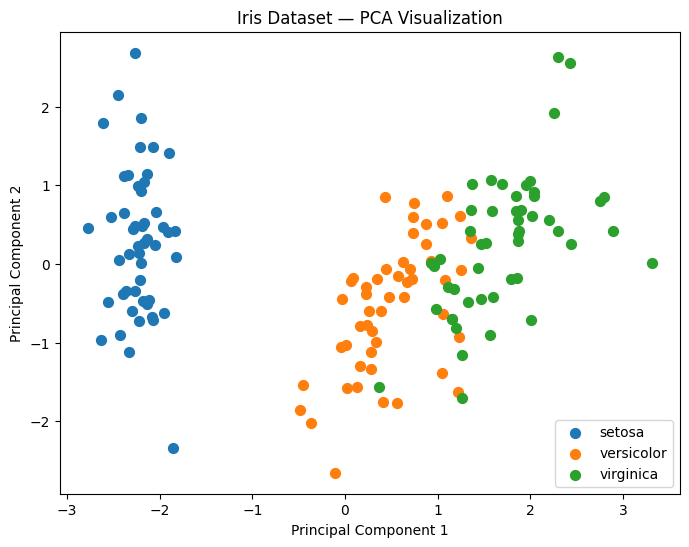

In [6]:
#Visualizing the PCA results
plt.figure(figsize=(8, 6))

for species_id, species_name in enumerate(iris.target_names):
    mask = y == species_id

    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=species_name,
        s=50
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Iris Dataset — PCA Visualization")
plt.legend()
plt.show()

In [7]:
#Explained variance ratio
explained_variance = pca.explained_variance_ratio_

print("PC1:", explained_variance[0])
print("PC2:", explained_variance[1])

print(
    "Total explained variance:",
    explained_variance.sum()
)

PC1: 0.7296244541329989
PC2: 0.22850761786701768
Total explained variance: 0.9581320720000166


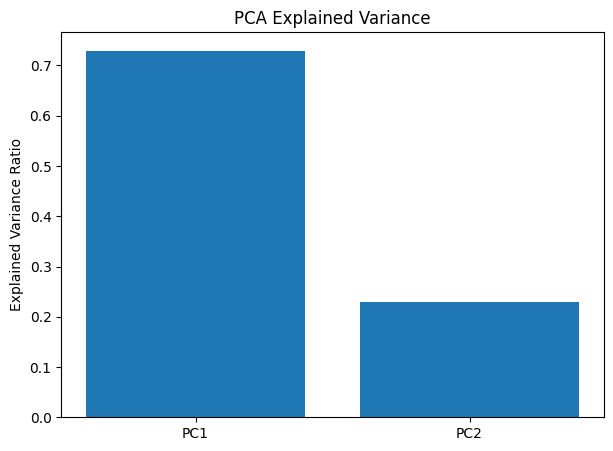

In [8]:
plt.figure(figsize=(7, 5))

plt.bar(
    ["PC1", "PC2"],
    explained_variance
)

plt.ylabel("Explained Variance Ratio")
plt.title("PCA Explained Variance")

plt.show()

In [9]:
#Cumulative explained variance
full_pca = PCA()

full_pca.fit(X_scaled)

cumulative_variance = np.cumsum(
    full_pca.explained_variance_ratio_
)

for i, value in enumerate(cumulative_variance, start=1):
    print(f"{i} components: {value:.2%}")

1 components: 72.96%
2 components: 95.81%
3 components: 99.48%
4 components: 100.00%


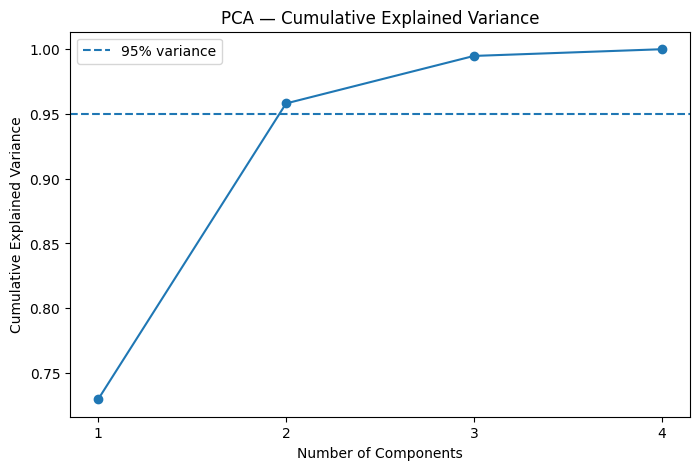

In [10]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 5),
    cumulative_variance,
    marker="o"
)

plt.axhline(
    y=0.95,
    linestyle="--",
    label="95% variance"
)

plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA — Cumulative Explained Variance")
plt.xticks(range(1, 5))
plt.legend()
plt.show()

In [11]:
#Automatically choose components
pca_95 = PCA(n_components=0.95)

X_pca_95 = pca_95.fit_transform(X_scaled)

print("Original dimensions:", X_scaled.shape[1])
print("Reduced dimensions:", X_pca_95.shape[1])

print(
    "Retained variance:",
    pca_95.explained_variance_ratio_.sum()
)

Original dimensions: 4
Reduced dimensions: 2
Retained variance: 0.9581320720000166


In [12]:
#Reconstruct data from PCA
reconstructed = pca.inverse_transform(X_pca)

print("Original first row:")
print(X_scaled[0])

print("Reconstructed first row:")
print(reconstructed[0])

Original first row:
[-0.90068117  1.01900435 -1.34022653 -1.3154443 ]
Reconstructed first row:
[-0.99888895  1.05319838 -1.30270654 -1.24709825]


In [13]:
reconstruction_error = np.mean(
    (X_scaled - reconstructed) ** 2
)

print("Reconstruction MSE:", reconstruction_error)

Reconstruction MSE: 0.041867927999983595
